<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/Practica_02_RegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Octubre 2026
## Práctica: Práctica: Regresión Con Datos Categorícos **Costos, localidades y salarios**
---


## Datos del Estudiante

*   Apellidos y Nombre: Lemus Rendon Cristobal
*   Matrícula: 274690

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, los estudiantes serán capaces de:

* Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
* Realizar AED
* Construir un modelo de regresión con variables dummy
* Interpretar los resultados de los coeficientes
* Analizar los resultados de los errores residuales
* Calcular el desempeño del modelo de regresión.





**Problema:** Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes **cost** y **location.**

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [11]:
# Importamos os para comprobar si existe el archivo en una ruta
import os
# Importamos pandas para manipular tablas (DataFrames)
import pandas as pd
# Importamos numpy para operaciones numéricas
import numpy as np
# Importamos matplotlib para crear gráficos
import matplotlib.pyplot as plt
# Importamos seaborn para gráficos estadísticos (histograma, dispersión, boxplot)
import seaborn as sns
# Importamos el módulo de estadística de scipy (prueba de normalidad, asimetría)
from scipy import stats
# Importamos la regresión lineal de Scikit-Learn
from sklearn.linear_model import LinearRegression
# Importamos las métricas de evaluación (MSE y R²)
from sklearn.metrics import mean_squared_error, r2_score
# Importamos statsmodels (API clásica) para el análisis de varianza
import statsmodels.api as sm
# Importamos la API de fórmulas de statsmodels (modelos con sintaxis tipo R)
import statsmodels.formula.api as smf
# Importamos la prueba de Breusch-Pagan para revisar si la varianza de los residuos es constante
from statsmodels.stats.diagnostic import het_breuschpagan

# Definimos un estilo visual limpio para todos los gráficos
sns.set_theme(style="whitegrid")

# Ruta del archivo (carpeta sample_data de Colab)
ruta = ['sample_data/college.csv']
# Elegimos la ruta
ruta = next(r for r in ruta if os.path.exists(r))
# Cargamos el archivo CSV completo en un DataFrame
df_completo = pd.read_csv(ruta)

# Nos quedamos solo con las columnas pedidas: salary (dependiente), cost y location (independientes)
df = df_completo[['salary', 'cost', 'location']].copy()
# Mostramos las primeras filas para revisar la carga
display(df.head())
# Mostramos las dimensiones (filas, columnas)
print("Dimensiones (filas, columnas):", df.shape)
# Revisamos si hay valores nulos en cada columna
print("Valores nulos por columna:\n", df.isnull().sum())

# Convertimos location a tipo de dato categórico
df['location'] = df['location'].astype('category')
# Verificamos los tipos de dato (location debe aparecer como category)
print("\nTipos de dato:\n", df.dtypes)

# describe() de las variables numéricas salary y cost
print("\nDescripción estadística de salary y cost:")
# round(2) limita a 2 decimales para leer mejor
display(df[['salary', 'cost']].describe().round(2))

# Cantidad de datos por categoría de location
print("Cantidad de universidades por location:")
# value_counts() cuenta las filas de cada categoría
print(df['location'].value_counts())

# One-hot encoding con K-1: drop_first=True elimina la primera categoría (MW) para evitar la trampa de variables dummy
dummies = pd.get_dummies(df['location'], prefix='location', drop_first=True, dtype=int)
# Unimos las variables dummy con salary y cost en un nuevo DataFrame para el modelo
df_modelo = pd.concat([df[['salary', 'cost']], dummies], axis=1)
# Mostramos las primeras filas del DataFrame codificado
print("\nDataFrame con one-hot encoding (K-1):")
# display muestra la tabla con formato en el notebook
display(df_modelo.head())

,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


Dimensiones (filas, columnas): (85, 3)
Valores nulos por columna:
 salary      0
cost        0
location    0
dtype: int64

Tipos de dato:
 salary         int64
cost           int64
location    category
dtype: object

Descripción estadística de salary y cost:


,salary,cost
count,85.00,85.00
mean,95898.82,142434.47
std,11937.12,53913.06
min,74900.00,18260.00
25%,87100.00,84670.00
50%,93200.00,169200.00
75%,105000.00,188700.00
max,123000.00,227300.00


Cantidad de universidades por location:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64

DataFrame con one-hot encoding (K-1):


,salary,cost,location_NE,location_S,location_W
0,119000,189300,1,0,0
1,121000,189600,1,0,0
2,123000,188400,1,0,0
3,123000,188700,1,0,0
4,110000,194200,1,0,0


**Interpretación Sección 1.**
- El conjunto tiene **85 universidades** y no hay valores nulos. `location` ya quedó como variable categórica con 4 categorías.
- **salary:** media ≈ \$95,899, mediana ≈ \$93,200, desviación ≈ \$11,937, rango de \$74,900 a \$123,000. **cost:** media ≈ \$142,434 y mediana ≈ \$169,200 (la mediana es mayor que la media, hay un grupo de universidades con costos bajos que jala el promedio hacia abajo); rango de \$18,260 a \$227,300.
- **Datos por categoría:** NE = 25, W = 21, S = 20 y MW = 19; las categorías están razonablemente balanceadas.
- **One-hot K-1:** con 4 categorías se crean solo **3 variables dummy** (`location_NE`, `location_S`, `location_W`). La categoría eliminada, **MW**, es la categoría de referencia: queda representada cuando las tres dummies valen 0.

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




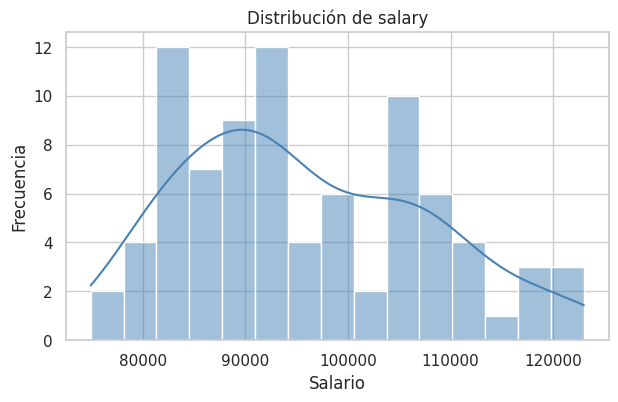

Asimetría (skew) de salary: 0.439


In [2]:
# Creamos la figura del histograma
plt.figure(figsize=(7, 4))
# Histograma de salary con la curva KDE (densidad estimada) superpuesta
sns.histplot(df['salary'], bins=15, kde=True, color='steelblue')
# Título del gráfico
plt.title('Distribución de salary')
# Etiqueta del eje X
plt.xlabel('Salario')
# Etiqueta del eje Y
plt.ylabel('Frecuencia')
# Mostramos el gráfico
plt.show()
# Imprimimos la asimetría de salary (positiva = cola larga a la derecha)
print(f"Asimetría (skew) de salary: {stats.skew(df['salary']):.3f}")

**Discusión (histograma de salary).** La distribución es **asimétrica a la derecha** (skew ≈ 0.44): la mayoría de las universidades tiene salarios entre ≈\$80,000 y \$105,000 y hay una cola hacia salarios altos (hasta \$123,000) que corresponde a un grupo pequeño de universidades de élite. No es perfectamente simétrica, pero no hay valores extremos aislados.

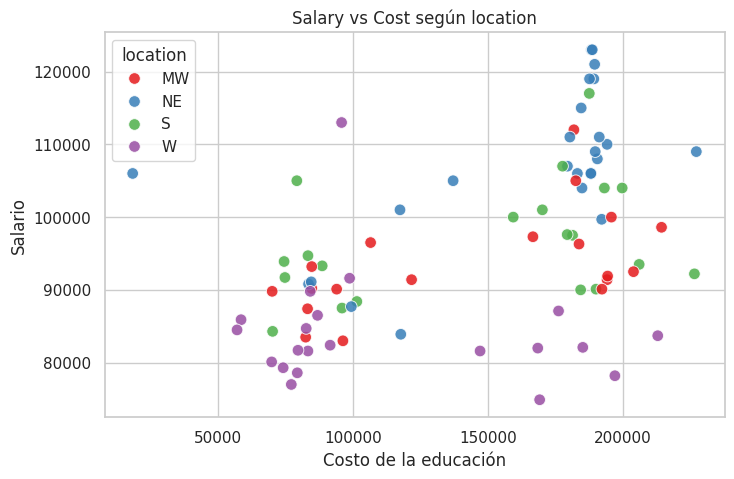

Correlación cost-salary: 0.480


In [3]:
# Creamos la figura del diagrama de dispersión
plt.figure(figsize=(8, 5))
# Dispersión salary vs cost; hue colorea cada punto según su location (4 colores distintos)
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='Set1', s=70, alpha=0.85)
# Título del gráfico
plt.title('Salary vs Cost según location')
# Etiqueta del eje X
plt.xlabel('Costo de la educación')
# Etiqueta del eje Y
plt.ylabel('Salario')
# Colocamos la leyenda con el nombre de la variable
plt.legend(title='location')
# Mostramos el gráfico
plt.show()
# Calculamos la correlación de Pearson entre cost y salary
print(f"Correlación cost-salary: {df['cost'].corr(df['salary']):.3f}")

**Discusión (dispersión salary vs cost).** Existe una **relación positiva moderada** (r ≈ 0.48): a mayor costo, tiende a haber mayor salario. Además se ven los colores **agrupados por zona**: los puntos de **NE** se concentran arriba y a la derecha (costos y salarios altos), mientras que los de **W** quedan más abajo y a la izquierda (costos y salarios menores). Los costos forman dos bloques (uno alrededor de \$70,000–\$120,000 y otro cerca de \$170,000–\$200,000), y por eso la nube de puntos no es una línea limpia. Esto sugiere que `location` aporta información adicional a `cost`.

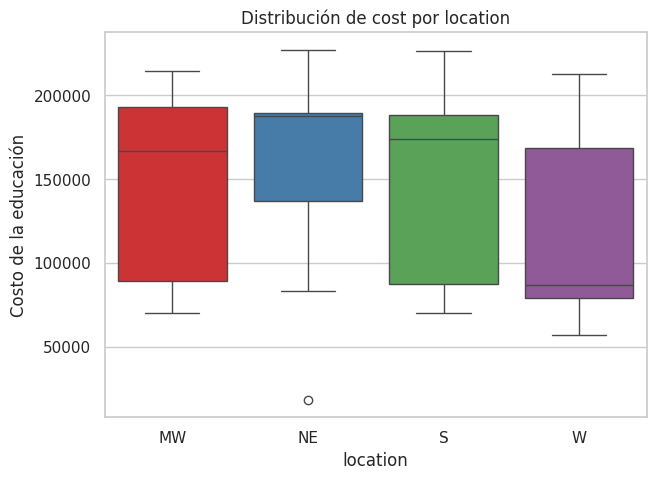

,count,mean,std,min,25%,50%,75%,max
location,,,,,,,,
MW,19.0,143859.0,52897.0,69990.0,89300.0,166700.0,193250.0,214400.0
NE,25.0,163035.0,48754.0,18260.0,137100.0,187700.0,189600.0,227300.0
S,20.0,146172.0,54620.0,70150.0,87222.0,173950.0,188225.0,226600.0
W,21.0,113062.0,50504.0,56970.0,79310.0,86820.0,168500.0,213000.0


In [4]:
# Creamos la figura del boxplot
plt.figure(figsize=(7, 5))
# Boxplot de cost para cada categoría de location
sns.boxplot(data=df, x='location', y='cost', palette='Set1', hue='location', legend=False)
# Título del gráfico
plt.title('Distribución de cost por location')
# Etiqueta del eje X
plt.xlabel('location')
# Etiqueta del eje Y
plt.ylabel('Costo de la educación')
# Mostramos el gráfico
plt.show()
# Mostramos la mediana y los cuartiles del costo por location para apoyar la lectura del gráfico
display(df.groupby('location', observed=True)['cost'].describe().round(0))

**Discusión (boxplot de cost por location).** Sí hay diferencias entre zonas. **W** tiene la **mediana más baja** (≈\$86,800) y una caja muy ancha (mezcla de universidades públicas baratas y privadas caras). **NE** tiene la mediana más alta (≈\$187,700); **S** (≈\$173,950) y **MW** (≈\$166,700) quedan en un nivel intermedio-alto. En MW, S y NE la mediana queda por encima de la media del grupo (p. ej., NE: mediana ≈\$187,700 vs. media ≈\$163,000), señal de distribuciones sesgadas a la izquierda. Esto es consistente con que el costo promedio y el salario cambien según la localidad.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [5]:
# Definimos las variables independientes: cost (numérica) y las 3 dummies de location
X = df_modelo[['cost', 'location_NE', 'location_S', 'location_W']]
# Definimos la variable dependiente: salary
y = df_modelo['salary']

# Creamos el modelo de regresión lineal
modelo = LinearRegression()
# Entrenamos el modelo con todos los datos (estima el intercepto y los coeficientes)
modelo.fit(X, y)

# Imprimimos el intercepto (β0): salario esperado de una universidad MW con cost = 0
print(f"Intercepto (β0): {modelo.intercept_:,.2f}")
# Recorremos cada variable junto con su coeficiente estimado
for nombre, coef in zip(X.columns, modelo.coef_):
    # Imprimimos el coeficiente (β) de cada variable
    print(f"Coeficiente de {nombre}: {coef:,.4f}")

# Mostramos la ecuación del modelo para facilitar la interpretación
print("\nSalary = {:.2f} + {:.4f}*cost + {:.2f}*NE + {:.2f}*S + {:.2f}*W".format(modelo.intercept_, *modelo.coef_))

Intercepto (β0): 84,988.72
Coeficiente de cost: 0.0605
Coeficiente de location_NE: 12,032.8197
Coeficiente de location_S: 2,800.3450
Coeficiente de location_W: -7,721.4201

Salary = 84988.72 + 0.0605*cost + 12032.82*NE + 2800.35*S + -7721.42*W


**Interpretación de los coeficientes.** Modelo: **Salary = 84,988.72 + 0.0605·cost + 12,032.82·NE + 2,800.35·S − 7,721.42·W**

- **Intercepto (≈\$84,989):** salario esperado para una universidad de la región de referencia **MW** (NE = S = W = 0) con costo igual a 0.
- **cost (≈0.0605):** manteniendo la región constante, cada \$1 adicional de costo se asocia con ≈\$0.06 más de salario; es decir, **cada \$10,000 más de costo ≈ +\$605 de salario**.
- **location_NE (≈+\$12,033):** a igual costo, una universidad del **Noreste gana en promedio \$12,033 más** que una de MW.
- **location_S (≈+\$2,800):** a igual costo, una del **Sur gana ≈\$2,800 más** que una de MW (diferencia pequeña; en la sección 6 se verá que no es significativa).
- **location_W (≈−\$7,721):** a igual costo, una del **Oeste gana ≈\$7,721 menos** que una de MW.

Los coeficientes de las dummies son **diferencias respecto a la categoría de referencia (MW)**, no respecto al promedio general. Para predecir se sustituye el costo y se pone en 1 la dummy de la región correspondiente (o las tres en 0 para MW). Ejemplo: una universidad de NE con costo 150,000 → 84,988.72 + 0.0605·150,000 + 12,032.82 ≈ \$106,100.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

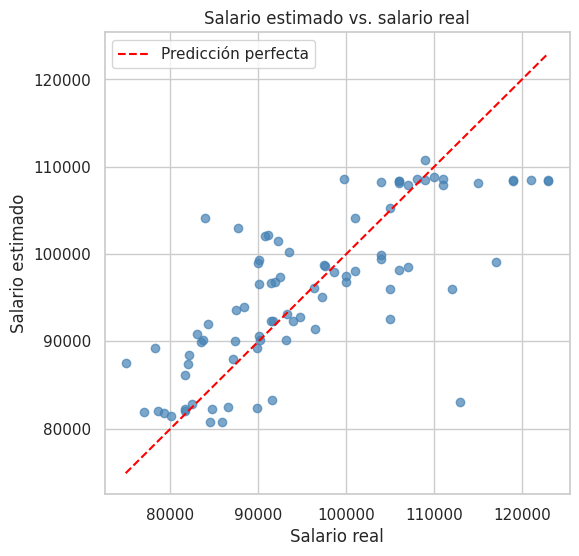

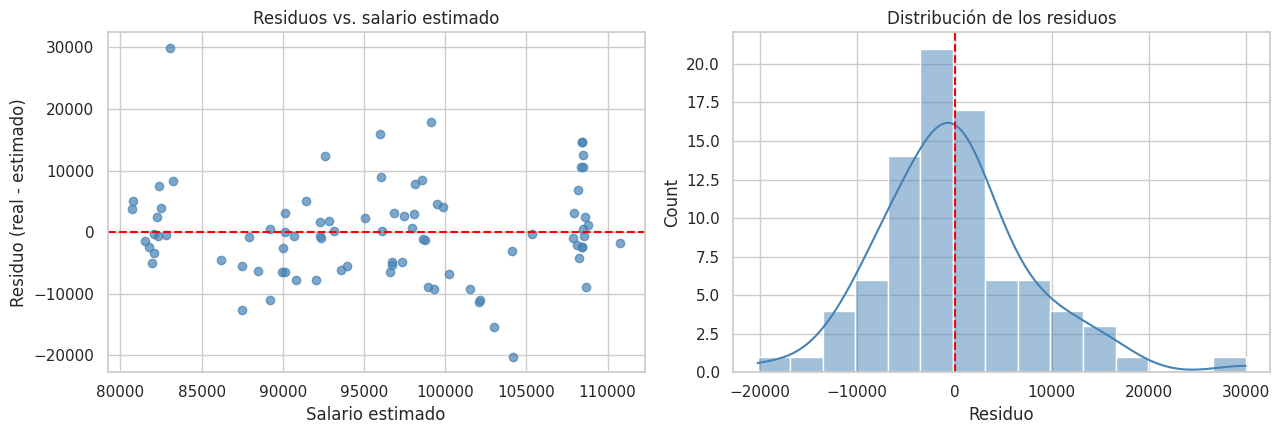

Shapiro-Wilk: estadístico = 0.9644, p-value = 0.0190
Asimetría (skew) de los residuos = 0.704
Breusch-Pagan: p-value = 0.7398


In [6]:
# Obtenemos el salario estimado por el modelo para cada universidad
y_pred = modelo.predict(X)
# Calculamos los residuos: salario real menos salario estimado
residuos = y - y_pred

# Creamos la figura del gráfico predicho vs real
plt.figure(figsize=(6, 6))
# Dispersión de salario real (X) contra salario estimado (Y)
plt.scatter(y, y_pred, alpha=0.7, color='steelblue')
# Calculamos los límites mínimo y máximo para trazar la diagonal
lim = [y.min(), y.max()]
# Línea diagonal y = x: si el modelo fuera perfecto todos los puntos caerían sobre ella
plt.plot(lim, lim, color='red', linestyle='--', label='Predicción perfecta')
# Etiqueta del eje X
plt.xlabel('Salario real')
# Etiqueta del eje Y
plt.ylabel('Salario estimado')
# Título del gráfico
plt.title('Salario estimado vs. salario real')
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

# Creamos una figura con dos gráficos para los errores residuales
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# Izquierda: residuos contra salario estimado
ax[0].scatter(y_pred, residuos, alpha=0.7, color='steelblue')
# Línea horizontal en 0 (los residuos deberían repartirse alrededor de ella)
ax[0].axhline(0, color='red', linestyle='--')
# Título del gráfico de residuos
ax[0].set_title('Residuos vs. salario estimado')
# Etiqueta del eje X
ax[0].set_xlabel('Salario estimado')
# Etiqueta del eje Y
ax[0].set_ylabel('Residuo (real - estimado)')
# Derecha: histograma de los residuos con KDE
sns.histplot(residuos, bins=15, kde=True, color='steelblue', ax=ax[1])
# Línea vertical en 0
ax[1].axvline(0, color='red', linestyle='--')
# Título del histograma
ax[1].set_title('Distribución de los residuos')
# Etiqueta del eje X
ax[1].set_xlabel('Residuo')
# Ajustamos espacios entre gráficos
plt.tight_layout()
# Mostramos la figura
plt.show()

# Prueba de Shapiro-Wilk: H0 = los residuos son normales
est_sw, p_sw = stats.shapiro(residuos)
# Imprimimos el resultado de la prueba
print(f"Shapiro-Wilk: estadístico = {est_sw:.4f}, p-value = {p_sw:.4f}")
# Imprimimos la asimetría de los residuos
print(f"Asimetría (skew) de los residuos = {stats.skew(residuos):.3f}")
# Prueba de Breusch-Pagan: H0 = varianza constante (homocedasticidad)
bp = het_breuschpagan(residuos, sm.add_constant(X))
# bp[1] es el p-value; lo imprimimos
print(f"Breusch-Pagan: p-value = {bp[1]:.4f}")

**Discusión (predicciones y residuos).**
- **Estimado vs. real:** los puntos siguen la tendencia de la diagonal pero con **dispersión considerable**; el modelo acierta la tendencia general, no el valor exacto de cada universidad. Tiende a subestimar los salarios más altos (puntos por encima de la diagonal en el eje del salario real).
- **Residuos vs. estimado:** se reparten alrededor de 0 **sin forma de embudo ni curvatura clara**. La prueba de Breusch-Pagan (H0: varianza constante) da p ≈ 0.74 > 0.05, por lo que **se cumple el supuesto de homocedasticidad**.
- **Histograma de residuos:** centrado en 0 pero con **cola derecha** (skew ≈ 0.70); Shapiro-Wilk (p ≈ 0.019 < 0.05) indica que la normalidad es solo aproximada. Los residuos más grandes son positivos: **Colorado School of Mines** (≈ +\$29,900, salario mucho mayor de lo esperado para su costo y región) y Duke (≈ +\$17,900); el más negativo es Penn State (≈ −\$20,200).

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [7]:
# MSE: promedio de los errores elevados al cuadrado (usamos el mismo conjunto de datos, sin train/test)
mse = mean_squared_error(y, y_pred)
# RMSE: raíz del MSE, queda en las mismas unidades que salary (dólares)
rmse = np.sqrt(mse)
# R²: proporción de la varianza de salary explicada por el modelo
r2 = r2_score(y, y_pred)

# Imprimimos el MSE
print(f"MSE  = {mse:,.2f}")
# Imprimimos el RMSE
print(f"RMSE = {rmse:,.2f}")
# Imprimimos el R² Score
print(f"R²   = {r2:.4f}")
# Imprimimos la desviación estándar de salary como referencia para juzgar el RMSE
print(f"Desviación estándar de salary = {y.std():,.2f}")

MSE  = 60,480,269.15
RMSE = 7,776.91
R²   = 0.5705
Desviación estándar de salary = 11,937.12


**Discusión de resultados.** MSE ≈ 60,480,269 (en dólares²), lo que equivale a un **RMSE ≈ \$7,777**: en promedio, el salario estimado se desvía ≈\$7,800 del real, frente a una desviación estándar de salary de ≈\$11,937. El **R² ≈ 0.571** indica que el costo y la localidad explican **≈57 %** de la variabilidad de los salarios. Es un ajuste **moderado**: el modelo captura una parte importante del comportamiento, pero queda ≈43 % sin explicar, posiblemente por otros factores no incluidos (tipo de universidad, carreras, prestigio, etc.). Como se evaluó sobre los mismos datos con que se entrenó, el desempeño real en datos nuevos podría ser algo menor.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [8]:
# Ajustamos con statsmodels el mismo modelo usando fórmula; C(location) trata location como categórica (dummies automáticas)
modelo_sm = smf.ols('salary ~ cost + C(location)', data=df).fit()
# Imprimimos el resumen con coeficientes, p-values y R²
print(modelo_sm.summary())

# Tabla ANOVA tipo II: prueba la contribución de cada variable controlando por la otra
tabla_anova = sm.stats.anova_lm(modelo_sm, typ=2)
# Mostramos la tabla ANOVA (sum_sq, df, F y PR(>F) = p-value)
print("\nTabla ANOVA (tipo II):")
# display muestra la tabla ANOVA con formato
display(tabla_anova)

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.96e-14
Time:                        03:19:42   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.499e+04   3092.65

,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN


**Interpretación del ANOVA.**
- **location:** F ≈ 21.12, p ≈ 3.6×10⁻¹⁰ (< 0.05). La localidad tiene un efecto **altamente significativo** sobre el salario y aporta la mayor suma de cuadrados (≈4.07×10⁹).
- **cost:** F ≈ 12.26, p ≈ 7.6×10⁻⁴ (< 0.05). El costo también es **significativo** (suma de cuadrados ≈7.9×10⁸), aunque aporta menos varianza explicada que la localidad.
- **Residual:** 80 grados de libertad y suma de cuadrados ≈5.14×10⁹ (variabilidad no explicada).
- Modelo global: F con p ≈ 5×10⁻¹⁴ y **R² ajustado ≈ 0.549**. En los coeficientes, NE (p < 0.001) y W (p ≈ 0.004) difieren significativamente de MW, pero **S no** (p ≈ 0.279): el Sur no se distingue de MW una vez controlado el costo.

In [9]:
# El enlace de la práctica trabaja con componentes de varianza (modelos mixtos); ajustamos un modelo con intercepto aleatorio por location
mixto = smf.mixedlm('salary ~ cost', data=df, groups=df['location']).fit(reml=True)
# Imprimimos el resumen (la fila "Group Var" es la varianza entre localidades)
print(mixto.summary())

# Varianza entre grupos (location) estimada por el modelo
var_grupo = float(mixto.cov_re.iloc[0, 0])
# Varianza residual (dentro de cada grupo)
var_resid = float(mixto.scale)
# Coeficiente de correlación intraclase: proporción de la varianza (tras controlar cost) debida a la localidad
icc = var_grupo / (var_grupo + var_resid)
# Imprimimos las varianzas y el ICC
print(f"\nVarianza entre localidades = {var_grupo:,.0f}")
# Imprimimos la varianza residual
print(f"Varianza residual          = {var_resid:,.0f}")
# Imprimimos el ICC
print(f"ICC (proporción atribuible a location) = {icc:.3f}")

             Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  salary       
No. Observations:    85       Method:              REML         
No. Groups:          4        Scale:               64259988.9170
Min. group size:     19       Log-Likelihood:      -883.7724    
Max. group size:     25       Converged:           Yes          
Mean group size:     21.2                                       
----------------------------------------------------------------
             Coef.     Std.Err.   z    P>|z|   [0.025    0.975] 
----------------------------------------------------------------
Intercept    86475.116 4755.851 18.183 0.000 77153.819 95796.412
cost             0.063    0.017  3.619 0.000     0.029     0.097
Group Var 63375113.891 6902.606                                 


Varianza entre localidades = 63,375,114
Varianza residual          = 64,259,989
ICC (proporción atribuible a location) = 0.497


**Interpretación de los componentes de varianza.** Con un intercepto aleatorio por localidad, la varianza **entre localidades** (≈63.4 millones) es casi igual a la **residual** (≈64.3 millones), por lo que el **ICC ≈ 0.50**: aproximadamente **la mitad de la variabilidad del salario (después de controlar el costo) se debe a diferencias entre localidades**. Esto confirma lo visto en el ANOVA: la localidad es un factor importante para explicar los salarios, además del costo. (Con solo 4 localidades, esta estimación es una referencia ilustrativa.)

**Conclusión general.** El costo de la educación y la localidad se relacionan significativamente con el salario: a mayor costo, mayor salario, y las universidades del **Noreste** ganan más y las del **Oeste** menos que las del **Medio Oeste**. El modelo explica ≈57 % de la variabilidad (RMSE ≈ \$7,777), cumple homocedasticidad y tiene normalidad de residuos solo aproximada.